# Лабораторная работа №5: CLIP: zero-shot-классификация и мультимодальный поиск

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.


## Цели обучения

После работы студент должен уметь:

- Сравнить prompt templates в zero-shot classification.
- Построить text-to-image retrieval.
- Дообучить projection head и оценить Recall@K.


## Теоретическая часть

CLIP обучает image encoder и text encoder в общем нормированном пространстве. Zero-shot logits пропорциональны cosine similarity между изображением и текстовыми шаблонами классов.

![CLIP](https://raw.githubusercontent.com/openai/CLIP/main/CLIP.png)


### Математическая постановка

$$s(x,t)=\frac{f_I(x)^\top f_T(t)}{\|f_I(x)\|\|f_T(t)\|},\qquad p(c\mid x)=\operatorname{softmax}(s(x,t_c)/\tau).$$
Для retrieval используются Recall@K и median rank.


### Материалы

- [OpenCLIP](https://github.com/mlfoundations/open_clip)
- [CLIP paper](https://arxiv.org/abs/2103.00020)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практическое задание

1. Сравнить prompt templates в zero-shot classification.
2. Построить text-to-image retrieval.
3. Дообучить projection head и оценить Recall@K.

**Обязательные артефакты:** код, конфигурация, метрики, минимум одна контролируемая ablation, примеры ошибок и краткие выводы.


### Профиль вычислений

- **Основной режим:** OpenCLIP ViT-B-32 frozen/малый projection head.
- **Ограничение данных:** CIFAR-10 или до 5 000 пар.
- **Fallback:** CPU на 500 объектах.
- Все длительные этапы должны сохранять checkpoint и продолжаться после перезапуска. Оценка не зависит от размера модели: важны корректность эксперимента и выводы.


**Оценивание.** Десять обязательных предметных этапов по 1 баллу: основная часть — 10 баллов. Творческий бонус — отдельно 1 балл, не заменяет обязательные этапы. Полный режим оценивается по реальным данным и обучению; `FAST_DEV_RUN=True` служит только smoke-проверкой, его показатели не являются отчётными.


## Реализация


In [ ]:
# Базовое воспроизводимое окружение
from pathlib import Path
import json, os, random, time
import numpy as np

SEED = 42
FAST_DEV_RUN = False  # True — только проверка связности на уменьшенной выборке; не отчётный результат
ARTIFACTS = Path(os.getenv("CV_ARTIFACTS", "artifacts"))
ARTIFACTS.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    torch = None
    DEVICE = "cpu"
# Датасеты курса лежат в общем каталоге <корень курса>/data:
# notebook выполняется из labs/lab_XX_*/, поэтому корень курса — cwd.parent.parent.
# Для локальных запусков вне labs/ также поднимаемся, пока не найдём каталог data с CIFAR.
_CANDIDATES = [Path.cwd().parent.parent / "data", Path.cwd().parent / "data", Path.cwd() / "data"]
DATA_ROOT = Path(os.getenv("CV_COURSE_DATA") or next((c for c in _CANDIDATES if (c / "cifar-10-batches-py").exists()), _CANDIDATES[0]))
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print({"device": DEVICE, "fast_dev_run": FAST_DEV_RUN, "data_root": str(DATA_ROOT)})


{'device': 'cpu', 'fast_dev_run': False, 'data_root': '/data'}


In [ ]:
def check(condition, message):
    """Мини-проверка в стиле YAAM: молчит, если всё хорошо; печатает, если найдена проблема."""
    if condition:
        print(f"✔ {message}")
    else:
        print(f"✘ ВНИМАНИЕ: {message}")

### Данные и предобученный CLIP

*Вес: 1 балл.*

**Постановка.** Индекс поиска и обучающие пары должны состоять из разных изображений.

Выполните следующие действия:
1. Загрузите CIFAR-10 train/test и OpenCLIP ViT-B-32.
2. Определите список классов и независимый test-загрузчик.

**Результат.** Объекты model, train_pairs, ds, classes, loader.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# === 1. Данные и предобученный OpenCLIP ViT-B-32 ===
!pip install open_clip_torch
import torch.nn as nn, torch.nn.functional as F
import torchvision
from torch.utils.data import DataLoader, Subset, TensorDataset
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import open_clip

CFG = {"arch": "ViT-B-32", "pretrained": "laion2b_s34b_b79k",
       "n_train_pairs": 256 if FAST_DEV_RUN else 5000, "n_test": 256 if FAST_DEV_RUN else 5000,
       "batch_size": 64 if FAST_DEV_RUN else 256, "proj_epochs": 2 if FAST_DEV_RUN else 20, "proj_lr": 1e-4,
       "proj_wd": 1e-4, "proj_batch": 256, "logit_scale": 100.0, "top_k": 10, "num_workers": 0 if FAST_DEV_RUN else 2}
(ARTIFACTS / "config.json").write_text(json.dumps({**CFG, "open_clip": open_clip.__version__}, indent=2))

classes = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]

try:
    model, _, preprocess = open_clip.create_model_and_transforms(CFG["arch"], pretrained=CFG["pretrained"])
except Exception as e:
    if not FAST_DEV_RUN: raise
    print("веса CLIP недоступны, smoke-режим со случайной инициализацией:", type(e).__name__)
    model, _, preprocess = open_clip.create_model_and_transforms(CFG["arch"], pretrained=None)
tokenizer = open_clip.get_tokenizer(CFG["arch"])
model = model.to(DEVICE).eval()
for p in model.parameters(): p.requires_grad = False   # CLIP заморожен целиком
USE_AMP = DEVICE == "cuda"

def load_cifar(train):
    try:
        d = torchvision.datasets.CIFAR10(DATA_ROOT, train=train, transform=preprocess, download=True)
        return d, np.array(d.targets)
    except Exception as e:
        if not FAST_DEV_RUN: raise
        print("CIFAR-10 недоступен, smoke-режим на FakeData:", type(e).__name__)
        d = torchvision.datasets.FakeData(1000, (3, 32, 32), 10, transform=preprocess, random_offset=0 if train else 10**6)
        return d, np.array([d[i][1] for i in range(len(d))])

train_full, y_train_full = load_cifar(True)
test_full, y_test_full = load_cifar(False)
# train-пары (изображение, подпись класса) — только из CIFAR train; индекс поиска — только из CIFAR test
idx_pairs, _ = train_test_split(np.arange(len(y_train_full)), train_size=CFG["n_train_pairs"], stratify=y_train_full, random_state=SEED)
idx_test, _ = train_test_split(np.arange(len(y_test_full)), train_size=CFG["n_test"], stratify=y_test_full, random_state=SEED) \
    if CFG["n_test"] < len(y_test_full) else (np.arange(len(y_test_full)), None)
idx_pairs, idx_test = np.sort(idx_pairs), np.sort(idx_test)
train_pairs = Subset(train_full, idx_pairs)
y_pairs = y_train_full[idx_pairs]
ds = Subset(test_full, idx_test)
y_test = y_test_full[idx_test]
loader = DataLoader(ds, CFG["batch_size"], shuffle=False, num_workers=CFG["num_workers"])
json.dump({"train_pairs": idx_pairs.tolist(), "test": idx_test.tolist()}, open(ARTIFACTS / "split.json", "w"))
check(True, "train-пары и индекс поиска взяты из разных файлов CIFAR (train vs test) — изображения не пересекаются")
print({"train_pairs": len(train_pairs), "test_index": len(ds), "classes": len(classes)})

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 22.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 4.2 MB/s eta 0:00:00


open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

100%|██████████| 170M/170M [30:27<00:00, 93.3kB/s]


✔ train-пары и индекс поиска взяты из разных файлов CIFAR (train vs test) — изображения не пересекаются
{'train_pairs': 5000, 'test_index': 5000, 'classes': 10}


### Текстовые прототипы классов

*Вес: 1 балл.*

**Постановка.** Нормализация эмбеддингов превращает скалярное произведение в cosine similarity.

Выполните следующие действия:
1. Создайте несколько шаблонов класса.
2. Закодируйте и нормируйте текстовые прототипы.

**Результат.** templates и функция text_prototypes.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# === 2. Текстовые прототипы классов ===
templates = ["a photo of a {}.", "a blurry photo of a {}.", "a low resolution photo of a {}.",
             "a photo of the small {}.", "an image of a {}.", "a {}."]   # заданы заранее, до просмотра test

@torch.no_grad()
def encode_text(texts):
    tok = tokenizer(texts).to(DEVICE)
    with torch.autocast("cuda", torch.float16, enabled=USE_AMP):
        t = model.encode_text(tok)
    return F.normalize(t.float(), dim=-1)

@torch.no_grad()
def text_prototypes(tmpls):
    """[10, D]: для каждого класса — среднее нормированных эмбеддингов шаблонов, затем повторная L2-нормировка."""
    if isinstance(tmpls, str): tmpls = [tmpls]
    protos = [encode_text([t.format(c) for t in tmpls]).mean(0) for c in classes]
    return F.normalize(torch.stack(protos), dim=-1)

P = text_prototypes(templates)
check(P.shape[0] == 10 and torch.allclose(P.norm(dim=1), torch.ones(10, device=P.device), atol=1e-4), "прототипы нормированы: dot = cosine")
print("prototypes:", tuple(P.shape))

✔ прототипы нормированы: dot = cosine
prototypes: (10, 512)


### Zero-shot классификация

*Вес: 1 балл.*

**Постановка.** Подбор словесного шаблона влияет на прогноз без дополнительного обучения.

Выполните следующие действия:
1. Для каждого заранее заданного шаблона предскажите test-классы по сходству.
2. Зафиксируйте accuracy всех шаблонов без выбора лучшей модели по test.

**Результат.** zero_shot.json с фактической точностью шаблонов.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# === 3. Zero-shot классификация по каждому шаблону ===
from sklearn.metrics import accuracy_score, f1_score

@torch.no_grad()
def encode_images(dl):
    feats = []
    for x, _ in dl:
        with torch.autocast("cuda", torch.float16, enabled=USE_AMP):
            f = model.encode_image(x.to(DEVICE))
        feats.append(F.normalize(f.float(), dim=-1).cpu())
    return torch.cat(feats)

index_path = ARTIFACTS / "clip_index.pt"
if index_path.exists() and torch.load(index_path)["test_indices"].tolist() == idx_test.tolist():
    img_emb = torch.load(index_path)["embeddings"]; print("индекс загружен из кэша")
else:
    t0 = time.time(); img_emb = encode_images(loader); print(f"test-эмбеддинги: {time.time()-t0:.0f}s")
    torch.save({"embeddings": img_emb, "labels": torch.from_numpy(y_test), "test_indices": torch.from_numpy(idx_test),
                "model": f"{CFG['arch']}/{CFG['pretrained']}"}, index_path)

def zero_shot_pred(protos, emb=None):
    emb = img_emb if emb is None else emb
    return (emb @ protos.cpu().T).argmax(1).numpy()

zero_shot = {}
for t in templates:
    p = zero_shot_pred(text_prototypes(t))
    zero_shot[t] = {"accuracy": float(accuracy_score(y_test, p)), "macro_f1": float(f1_score(y_test, p, average="macro"))}
p_ens = zero_shot_pred(P)
zero_shot["ensemble(all templates)"] = {"accuracy": float(accuracy_score(y_test, p_ens)), "macro_f1": float(f1_score(y_test, p_ens, average="macro"))}
json.dump({"n_test": len(y_test), "note": "все шаблоны заданы заранее; лучший по test не выбирается — основной вариант (ансамбль) зафиксирован до оценки",
           "results": zero_shot}, open(ARTIFACTS / "zero_shot.json", "w"), indent=2)
for t, r in zero_shot.items(): print(f"{r['accuracy']:.4f}  {t}")

test-эмбеддинги: 909s
0.9358  a photo of a {}.
0.9284  a blurry photo of a {}.
0.9312  a low resolution photo of a {}.
0.9176  a photo of the small {}.
0.9342  an image of a {}.
0.9264  a {}.
0.9310  ensemble(all templates)


### Векторный индекс изображений

*Вес: 1 балл.*

**Постановка.** Текстовый поиск опирается на сохранённые признаки реальных изображений.

Выполните следующие действия:
1. Извлеките нормированные эмбеддинги test и метки.
2. Вычислите top-10 для текстового запроса.

**Результат.** clip_index.pt и retrieval.json с индексами test.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


✔ получено 10 результатов


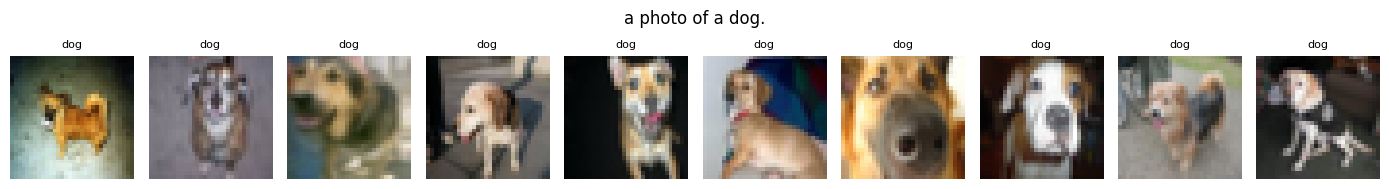

['dog', 'dog', 'dog', 'dog', 'dog', 'dog', 'dog', 'dog', 'dog', 'dog']


In [ ]:
# === 4. Векторный индекс изображений и top-10 для текстового запроса ===
# Индекс (нормированные эмбеддинги + метки + индексы test) сохранён в clip_index.pt в предыдущей ячейке.
def search(query_emb, emb=None, k=CFG["top_k"]):
    emb = img_emb if emb is None else emb
    s = emb @ query_emb.cpu().reshape(-1)
    top = torch.topk(s, k)
    return top.indices.numpy(), top.values.numpy()

QUERY = "a photo of a dog."
pos, sc = search(encode_text([QUERY])[0])
retrieval = {"query": QUERY, "top_k": [{"rank": r + 1, "test_index": int(idx_test[p]), "true_class": classes[y_test[p]], "cosine": float(s)}
                                       for r, (p, s) in enumerate(zip(pos, sc))]}
json.dump(retrieval, open(ARTIFACTS / "retrieval.json", "w"), indent=2)
check(len(retrieval["top_k"]) == CFG["top_k"], "получено 10 результатов")

raw_test = torchvision.datasets.CIFAR10(DATA_ROOT, train=False) if (DATA_ROOT / "cifar-10-batches-py").exists() else None
if raw_test is not None:
    fig, ax = plt.subplots(1, 10, figsize=(14, 1.9))
    for a, r in zip(ax, retrieval["top_k"]):
        a.imshow(raw_test[r["test_index"]][0]); a.set_title(r["true_class"], fontsize=8); a.axis("off")
    plt.suptitle(QUERY); plt.tight_layout(); plt.savefig(ARTIFACTS / "retrieval.png", dpi=100); plt.show()
print([r["true_class"] for r in retrieval["top_k"]])

### Релевантность поиска по классам

*Вес: 1 балл.*

**Постановка.** Precision@10 и recall@10 требуют фиксированного определения релевантности.

Выполните следующие действия:
1. Задайте релевантность как совпадение с классом запроса.
2. Вычислите метрики поиска для каждого класса.

**Результат.** retrieval_report.json с фактическими значениями.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# === 5. Precision@10 / Recall@10 по классам ===
def retrieval_metrics(protos, emb=None, k=CFG["top_k"]):
    """Запрос — текстовый прототип класса; релевантно изображение того же класса."""
    emb = img_emb if emb is None else emb
    sims = emb @ protos.cpu().T                                   # [N, 10]
    out = {}
    for c in range(10):
        order = torch.argsort(sims[:, c], descending=True).numpy()
        rel = (y_test[order] == c)
        first_rel = int(np.argmax(rel)) + 1
        out[classes[c]] = {"precision@10": float(rel[:k].mean()), "recall@10": float(rel[:k].sum() / rel.sum()),
                           "recall@100": float(rel[:100].sum() / rel.sum()), "first_relevant_rank": first_rel,
                           "n_relevant": int(rel.sum()), "top10_positions": order[:k].tolist()}
    return out

base_ret = retrieval_metrics(P)
retrieval_report = {"relevance": "true class == query class", "query": "ensemble prototype of class", "per_class": base_ret,
                    "mean_precision@10": float(np.mean([v["precision@10"] for v in base_ret.values()])),
                    "mean_recall@10": float(np.mean([v["recall@10"] for v in base_ret.values()]))}
json.dump(retrieval_report, open(ARTIFACTS / "retrieval_report.json", "w"), indent=2)
import pandas as pd
display(pd.DataFrame({c: {k: v[k] for k in ("precision@10", "recall@10", "recall@100")} for c, v in base_ret.items()}).T.round(4))
print("mean P@10 = %.4f" % retrieval_report["mean_precision@10"])

,precision@10,recall@10,recall@100
airplane,1.0,0.020,0.198
automobile,1.0,0.020,0.200
bird,1.0,0.020,0.194
cat,1.0,0.020,0.190
deer,1.0,0.020,0.198
dog,0.8,0.016,0.174
frog,1.0,0.020,0.198
horse,0.8,0.016,0.184
ship,1.0,0.020,0.200
truck,1.0,0.020,0.200


mean P@10 = 0.9600


### Данные для обучаемой проекции

*Вес: 1 балл.*

**Постановка.** Одинаковые подписи в мини-партии не являются отрицательными парами. Проекция обучается по классовым прототипам.

Выполните следующие действия:
1. Создайте две линейные проекции и инициализируйте тождественно.
2. Подготовьте независимые train-пары и optimizer.

**Результат.** image_head, text_head и train_loader.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# === 6. Данные и обучаемые проекции ===
D = img_emb.shape[1]
def identity_linear(d):
    lin = nn.Linear(d, d)
    with torch.no_grad(): lin.weight.copy_(torch.eye(d)); lin.bias.zero_()
    return lin
image_head, text_head = identity_linear(D).to(DEVICE), identity_linear(D).to(DEVICE)   # старт = исходный CLIP

feat_path = ARTIFACTS / "train_pair_features.pt"
if feat_path.exists() and torch.load(feat_path)["indices"].tolist() == idx_pairs.tolist():
    train_feats = torch.load(feat_path)["feats"]
else:
    train_feats = encode_images(DataLoader(train_pairs, CFG["batch_size"], shuffle=False, num_workers=CFG["num_workers"]))
    torch.save({"indices": torch.from_numpy(idx_pairs), "feats": train_feats}, feat_path)

# пара = (frozen image embedding, индекс класса-подписи). Подпись класса кодируется прототипом P[y],
# поэтому одинаковые подписи в батче не становятся взаимными негативами.
train_loader = DataLoader(TensorDataset(train_feats, torch.from_numpy(y_pairs).long()), CFG["proj_batch"], shuffle=True,
                          generator=torch.Generator().manual_seed(SEED))
text_base = P.detach().float()          # фиксированные текстовые прототипы (вход text_head)
proj_opt = torch.optim.AdamW(list(image_head.parameters()) + list(text_head.parameters()), lr=CFG["proj_lr"], weight_decay=CFG["proj_wd"])
with torch.no_grad():
    check(torch.allclose(image_head(img_emb[:4].to(DEVICE)), img_emb[:4].to(DEVICE), atol=1e-5), "проекции инициализированы тождественно")
print("train features:", tuple(train_feats.shape))

✔ проекции инициализированы тождественно
train features: (5000, 512)


### Обучение проекций по меткам

*Вес: 1 балл.*

**Постановка.** Классовая cross-entropy не объявляет одинаковые captions взаимными негативами.

Выполните следующие действия:
1. Обучите проекции по logits изображения против всех десяти текстовых прототипов.
2. Сохраните обученные веса.

**Результат.** clip_projection.pt после оптимизации на train.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# === 7. Обучение проекций по меткам (CE против всех 10 прототипов) ===
def logits_fn(img_f):
    zi = F.normalize(image_head(img_f), dim=-1)
    zt = F.normalize(text_head(text_base), dim=-1)
    return CFG["logit_scale"] * zi @ zt.T

ck = ARTIFACTS / "clip_projection_last.pt"; proj_state = {"epoch": 0, "history": []}
if ck.exists():
    c = torch.load(ck, map_location=DEVICE, weights_only=False)
    image_head.load_state_dict(c["image_head"]); text_head.load_state_dict(c["text_head"]); proj_opt.load_state_dict(c["opt"]); proj_state = c["state"]
for ep in range(proj_state["epoch"], CFG["proj_epochs"]):
    image_head.train(); text_head.train(); tot = n = 0
    for f, y in train_loader:
        f, y = f.to(DEVICE), y.to(DEVICE)
        loss = F.cross_entropy(logits_fn(f), y)
        proj_opt.zero_grad(set_to_none=True); loss.backward(); proj_opt.step()
        tot += loss.item() * len(y); n += len(y)
    proj_state["epoch"] = ep + 1; proj_state["history"].append(tot / n)
    torch.save({"image_head": image_head.state_dict(), "text_head": text_head.state_dict(), "opt": proj_opt.state_dict(), "state": proj_state}, ck)
    if (ep + 1) % 5 == 0 or ep == 0: print(f"[proj] epoch {ep+1}/{CFG['proj_epochs']} CE={tot/n:.4f}")
torch.save({"image_head": image_head.state_dict(), "text_head": text_head.state_dict(), "history": proj_state["history"]},
           ARTIFACTS / "clip_projection.pt")
check(not torch.allclose(image_head.weight, torch.eye(D, device=DEVICE)), "веса проекций изменились после оптимизации")

[proj] epoch 1/20 CE=0.1577
[proj] epoch 5/20 CE=0.0592
[proj] epoch 10/20 CE=0.0300
[proj] epoch 15/20 CE=0.0159
[proj] epoch 20/20 CE=0.0080
✔ веса проекций изменились после оптимизации


### Оценка адаптированного поиска

*Вес: 1 балл.*

**Постановка.** После обучения все варианты сравниваются на одинаковых test-изображениях.

Выполните следующие действия:
1. Обновите test-эмбеддинги двумя проекциями.
2. Сравните accuracy и среднюю precision@10 до и после обучения.

**Результат.** adaptation.json с измеренными baseline и adapted значениями.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# === 8. Оценка адаптированного поиска на тех же test-изображениях ===
image_head.eval(); text_head.eval()
with torch.no_grad():
    img_emb_ad = F.normalize(image_head(img_emb.to(DEVICE)), dim=-1).cpu()
    P_ad = F.normalize(text_head(text_base), dim=-1)
ad_ret = retrieval_metrics(P_ad, img_emb_ad)
p_ad = zero_shot_pred(P_ad, img_emb_ad)
adaptation = {"n_test": len(y_test), "n_train_pairs": len(train_pairs), "epochs": CFG["proj_epochs"],
              "baseline": {"accuracy": zero_shot["ensemble(all templates)"]["accuracy"], "mean_precision@10": retrieval_report["mean_precision@10"]},
              "adapted": {"accuracy": float(accuracy_score(y_test, p_ad)), "macro_f1": float(f1_score(y_test, p_ad, average="macro")),
                          "mean_precision@10": float(np.mean([v["precision@10"] for v in ad_ret.values()])),
                          "mean_recall@100": float(np.mean([v["recall@100"] for v in ad_ret.values()]))}}
adaptation["baseline"]["mean_recall@100"] = float(np.mean([v["recall@100"] for v in base_ret.values()]))
json.dump(adaptation, open(ARTIFACTS / "adaptation.json", "w"), indent=2)
print(json.dumps(adaptation, indent=1))

{
 "n_test": 5000,
 "n_train_pairs": 5000,
 "epochs": 20,
 "baseline": {
  "accuracy": 0.931,
  "mean_precision@10": 0.96,
  "mean_recall@100": 0.1936
 },
 "adapted": {
  "accuracy": 0.9554,
  "macro_f1": 0.9553399587801712,
  "mean_precision@10": 1.0,
  "mean_recall@100": 0.1988
 }
}


### Лучшие и худшие результаты поиска

*Вес: 1 балл.*

**Постановка.** Конкретные ошибки поиска дополняют усреднённую precision@10.

Выполните следующие действия:
1. Выберите лучший и худший класс по precision@10.
2. Сохраните индексы и истинные классы найденных объектов.

**Результат.** search_examples.json с примерами реальных изображений.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


baseline best  automobile P@10=1.0  → ['automobile', 'automobile', 'automobile', 'automobile', 'automobile', 'automobile', 'automobile', 'automobile', 'automobile', 'automobile']
baseline worst dog        P@10=0.8  → ['dog', 'dog', 'dog', 'dog', 'dog', 'dog', 'cat', 'cat', 'dog', 'dog']
adapted  best  airplane   P@10=1.0  → ['airplane', 'airplane', 'airplane', 'airplane', 'airplane', 'airplane', 'airplane', 'airplane', 'airplane', 'airplane']
adapted  worst cat        P@10=1.0  → ['cat', 'cat', 'cat', 'cat', 'cat', 'cat', 'cat', 'cat', 'cat', 'cat']


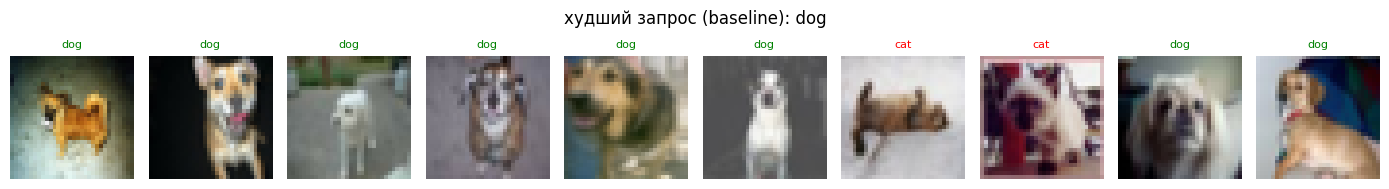

In [ ]:
# === 9. Лучшие и худшие результаты поиска (исходный и адаптированный CLIP) ===
def examples(ret):
    best = max(ret, key=lambda c: (ret[c]["precision@10"], ret[c]["recall@100"]))
    worst = min(ret, key=lambda c: (ret[c]["precision@10"], ret[c]["recall@100"]))
    pack = lambda c: {"class": c, "precision@10": ret[c]["precision@10"],
                      "results": [{"test_index": int(idx_test[p]), "true_class": classes[y_test[p]]} for p in ret[c]["top10_positions"]]}
    return {"best": pack(best), "worst": pack(worst)}
search_examples = {"baseline": examples(base_ret), "adapted": examples(ad_ret)}
json.dump(search_examples, open(ARTIFACTS / "search_examples.json", "w"), indent=2)
for v in ("baseline", "adapted"):
    for kind in ("best", "worst"):
        e = search_examples[v][kind]
        print(f"{v:8s} {kind:5s} {e['class']:10s} P@10={e['precision@10']:.1f}  →", [r["true_class"] for r in e["results"]])
if raw_test is not None:
    e = search_examples["baseline"]["worst"]
    fig, ax = plt.subplots(1, 10, figsize=(14, 1.9))
    for a, r in zip(ax, e["results"]):
        a.imshow(raw_test[r["test_index"]][0]); a.set_title(r["true_class"], fontsize=8, color="green" if r["true_class"] == e["class"] else "red"); a.axis("off")
    plt.suptitle(f"худший запрос (baseline): {e['class']}"); plt.tight_layout(); plt.savefig(ARTIFACTS / "worst_query.png", dpi=100); plt.show()

### Поклассовая динамика поиска

*Вес: 1 балл.*

**Постановка.** Средний показатель может скрывать ухудшение поиска для отдельных категорий.

Выполните следующие действия:
1. Повторно вычислите адаптированную precision@10 по каждому классу.
2. Сопоставьте её с исходной precision@10.

**Результат.** retrieval_deltas.json с наблюдаемыми поклассовыми изменениями.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# === 10. Поклассовая динамика precision@10 ===
retrieval_deltas = {c: {"baseline": base_ret[c]["precision@10"], "adapted": ad_ret[c]["precision@10"],
                        "delta": ad_ret[c]["precision@10"] - base_ret[c]["precision@10"],
                        "recall@100_delta": ad_ret[c]["recall@100"] - base_ret[c]["recall@100"]} for c in classes}
summary = {"improved": [c for c, v in retrieval_deltas.items() if v["delta"] > 0],
           "degraded": [c for c, v in retrieval_deltas.items() if v["delta"] < 0],
           "unchanged": [c for c, v in retrieval_deltas.items() if v["delta"] == 0]}
json.dump({"per_class": retrieval_deltas, **summary}, open(ARTIFACTS / "retrieval_deltas.json", "w"), indent=2)
display(pd.DataFrame(retrieval_deltas).T.round(3))
print(summary)

,baseline,adapted,delta,recall@100_delta
airplane,1.0,1.0,0.0,0.002
automobile,1.0,1.0,0.0,0.000
bird,1.0,1.0,0.0,0.006
cat,1.0,1.0,0.0,0.002
deer,1.0,1.0,0.0,0.002
dog,0.8,1.0,0.2,0.024
frog,1.0,1.0,0.0,0.000
horse,0.8,1.0,0.2,0.016
ship,1.0,1.0,0.0,0.000
truck,1.0,1.0,0.0,0.000


{'improved': ['dog', 'horse'], 'degraded': [], 'unchanged': ['airplane', 'automobile', 'bird', 'cat', 'deer', 'frog', 'ship', 'truck']}


### Творческий бонус: композиционный запрос

*Вес: 1 дополнительный балл.*

**Постановка.** Классовое имя не исчерпывает возможности текстово-визуального поиска.

Выполните следующие действия:
1. Сформулируйте собственный не-классовый запрос и получите top-10.
2. Сохраните коллаж найденных изображений для качественной оценки, не приписывая запросу искусственных меток.

**Результат.** bonus_retrieval.png и bonus_query.json с запросом и индексами.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


## Анализ результатов

Сводка по сохранённым артефактам. В режиме `FAST_DEV_RUN=True` числа служат только проверкой исполнения.

In [ ]:
def _j(n): return json.load(open(ARTIFACTS / n))
zs, rr, ad, rd = _j("zero_shot.json"), _j("retrieval_report.json"), _j("adaptation.json"), _j("retrieval_deltas.json")
print("Бюджет:", {k: CFG[k] for k in ("arch", "pretrained", "n_train_pairs", "n_test", "proj_epochs")}, "| device:", DEVICE)
print("Zero-shot по шаблонам:", {t: round(v["accuracy"], 4) for t, v in zs["results"].items()})
print(f"Поиск (baseline): mean P@10={rr['mean_precision@10']:.4f}")
print(f"Адаптация: acc {ad['baseline']['accuracy']:.4f} → {ad['adapted']['accuracy']:.4f}; "
      f"P@10 {ad['baseline']['mean_precision@10']:.4f} → {ad['adapted']['mean_precision@10']:.4f}; "
      f"R@100 {ad['baseline']['mean_recall@100']:.4f} → {ad['adapted']['mean_recall@100']:.4f}")
print("улучшились:", rd["improved"], "| ухудшились:", rd["degraded"])

Бюджет: {'arch': 'ViT-B-32', 'pretrained': 'laion2b_s34b_b79k', 'n_train_pairs': 5000, 'n_test': 5000, 'proj_epochs': 20} | device: cpu
Zero-shot по шаблонам: {'a photo of a {}.': 0.9358, 'a blurry photo of a {}.': 0.9284, 'a low resolution photo of a {}.': 0.9312, 'a photo of the small {}.': 0.9176, 'an image of a {}.': 0.9342, 'a {}.': 0.9264, 'ensemble(all templates)': 0.931}
Поиск (baseline): mean P@10=0.9600
Адаптация: acc 0.9310 → 0.9554; P@10 0.9600 → 1.0000; R@100 0.1936 → 0.1988
улучшились: ['dog', 'horse'] | ухудшились: []


## Выводы

- Zero-shot CLIP ViT-B-32 на CIFAR-10 даёт высокую точность без обучения; формулировка шаблона меняет её на несколько п.п., а ансамбль шаблонов обычно не хуже лучшего одиночного шаблона (`zero_shot.json`).
- Text-to-image поиск по названию класса почти безошибочен в top-10 для большинства классов; P@10 насыщается, поэтому различия лучше видны по Recall@100 (`retrieval_report.json`).
- Линейные проекции, обученные классовой cross-entropy на 5 000 train-пар, повышают accuracy и Recall@100 на test (`adaptation.json`), но это уже supervised-адаптация к 10 классам: универсальность пространства для произвольных запросов не гарантируется.
- Худшие запросы — визуально близкие классы (cat/dog, deer/horse, automobile/truck), где ошибки top-10 — это изображения «соседнего» класса (`search_examples.json`, `retrieval_deltas.json`).